# NB12 — Visualización: Hipótesis Fierro ↔ Respuesta vOS ↔ Grafo Epistémico

**Objetivo:** Gráficos significativos que correlacionan las 3 objeciones de Prof. Raúl Fierro, nuestra respuesta matemática (addendum), y el grafo epistémico vivo.

**Fierro cuestionó (2026-06-29):**
- **Q1:** Convexidad de Ω (Brouwer no aplica — Ω no es convexo)
- **Q2:** Invariancia de f₀ (proyección deforma la dinámica)
- **Q3:** Ruido no acotado (invariancia puntual = falso)

**Respuesta (addendum math-register 2026-07-13):**
- **Prop1:** Existencia sin convexidad (Krylov-Bogolyubov + Banach)
- **Prop2:** Viabilidad estocástica (Foster-Lyapunov drift, Meyn-Tweedie)
- **L_f medido:** [1.4, 24.4] — no-expansivo OFF-core, confinement medido

**R10:** Determinista. **NO-NEW-TRUTH:** Visualización de datos existentes.

Plan: `docs/plans/nb12_fierro_visualization.vsm` (ratified).

In [1]:
import sys, json
sys.path.insert(0, "packages/framework")
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import numpy as np
import networkx as nx
from pathlib import Path

from epistemic_graph import build, by_kind, by_edge, communities

print(f"imports OK — matplotlib {matplotlib.__version__}, networkx {nx.__version__}")

imports OK — matplotlib 3.10.7+dfsg1, networkx 3.4.2


In [2]:
# CELL 1: MAPA Fierro — 3 objeciones Q1/Q2/Q3 como nodos
fierro_objections = {
    "Q1": {
        "topic": "convexidad de Ω",
        "claim": "Ω = ∩ᵢ{x : Aᵢ(x) ≥ 0} no es convexo (upper level set de concava + predico no geométrico)",
        "consequence": "Brouwer no aplica → existencia no demostrada",
        "severity": "STRONG",
    },
    "Q2": {
        "topic": "invariancia de f₀",
        "claim": "f₀(Ω) ⊆ Ω impuesto por proyección deforma la dinámica",
        "consequence": "Si f₀ deforma, el fixed point no es el del sistema real",
        "severity": "MEDIUM",
    },
    "Q3": {
        "topic": "ruido no acotado",
        "claim": "ση_t con soporte no acotado → invariancia puntual x_{t+1} ∈ Ω a.s. es falso",
        "consequence": "Noción correcta: viabilidad estocástica (Aubin)",
        "severity": "MEDIUM",
    },
}
print("FIerro objections map:")
for q, d in fierro_objections.items():
    print(f"  {q} [{d['severity']}]: {d['topic']}")
    print(f"      claim: {d['claim'][:80]}...")

FIerro objections map:
  Q1 [STRONG]: convexidad de Ω
      claim: Ω = ∩ᵢ{x : Aᵢ(x) ≥ 0} no es convexo (upper level set de concava + predico no geo...
  Q2 [MEDIUM]: invariancia de f₀
      claim: f₀(Ω) ⊆ Ω impuesto por proyección deforma la dinámica...
  Q3 [MEDIUM]: ruido no acotado
      claim: ση_t con soporte no acotado → invariancia puntual x_{t+1} ∈ Ω a.s. es falso...


In [3]:
# CELL 2: RESPUESTA — 3 proposiciones del addendum math-register
response = {
    "Q1": {
        "solution": "Prop1: Existencia SIN convexidad",
        "tools": ["Krylov-Bogolyubov (Feller + compacto)", "Banach (contracción en Ω_A)", "Foster-Lyapunov (unicidad)"]
    },
    "Q2": {
        "solution": "Confinamiento medido, no impuesto",
        "tools": ["λ_max = ln(0.99) < 0 (Benettin)", "L_f ∈ [1.4, 24.4] (código desplegado)", "Zero exits N=3000/level"]
    },
    "Q3": {
        "solution": "Prop2: Viabilidad estocástica",
        "tools": ["Foster-Lyapunov drift", "Meyn-Tweedie ergodicity", "Empirical exit rate < 3/N"]
    },
}
print("RESPONSE map:")
for q, d in response.items():
    print(f"  {q} → {d['solution']}")
    for t in d["tools"]:
        print(f"      · {t}")

RESPONSE map:
  Q1 → Prop1: Existencia SIN convexidad
      · Krylov-Bogolyubov (Feller + compacto)
      · Banach (contracción en Ω_A)
      · Foster-Lyapunov (unicidad)
  Q2 → Confinamiento medido, no impuesto
      · λ_max = ln(0.99) < 0 (Benettin)
      · L_f ∈ [1.4, 24.4] (código desplegado)
      · Zero exits N=3000/level
  Q3 → Prop2: Viabilidad estocástica
      · Foster-Lyapunov drift
      · Meyn-Tweedie ergodicity
      · Empirical exit rate < 3/N


In [4]:
# CELL 3: GRAFO — subgrafo Fierro: claims de los sidecars
g = build()
print(f"Full graph: {g['meta']['nodes_total']} nodes, {g['meta']['edges_total']} edges")

# Extract Fierro-related claims by source_id
fierro_nodes = [n for n in g["nodes"] if "FIERRO" in n.get("id","").upper() or "fierro" in n.get("label","").lower()]
print(f"\nFierro-related nodes: {len(fierro_nodes)}")
for n in fierro_nodes[:10]:
    print(f"  {n['id'][:50]:<50} kind={n.get('kind','?')}")

# Also get nodes from carta_acompanamiento and addendum sources
carta_nodes = [n for n in g["nodes"] if "CARTA" in n.get("id","").upper()]
addendum_nodes = [n for n in g["nodes"] if "ADDENDUM" in n.get("id","").upper()]
print(f"\nCarta nodes: {len(carta_nodes)}, Addendum nodes: {len(addendum_nodes)}")

Full graph: 2227 nodes, 4962 edges

Fierro-related nodes: 12
  claim:SRC-ADDENDUM-6a13177d|551cf1346aecafb2       kind=claim
  claim:SRC-ADDENDUM-6a13177d|eccca197f41cbdd0       kind=claim
  claim:SRC-ADDENDUM-6a13177d|eccca197f41cbdd0#2     kind=claim
  claim:SRC-MAIN-6edd9ece|4ec18570271ddb33           kind=claim
  claim:SRC-README-d2e9a6c2|233129e0d4cd2383         kind=claim
  claim:SRC-README-d2e9a6c2|5dd19445a1c1ddea         kind=claim
  claim:SRC-REV-PROF-RAUL-FIERRO-c777fb7d|88fab315c8 kind=claim
  claim:SRC-TASKS-3b17167e|49e5a938fc9d4b76          kind=claim
  claim:SRC-TASKS-3b17167e|6b9447018c0bd2e2          kind=claim
  claim:SRC-TASKS-3b17167e|c7bc109a9202ae98          kind=claim

Carta nodes: 6, Addendum nodes: 26


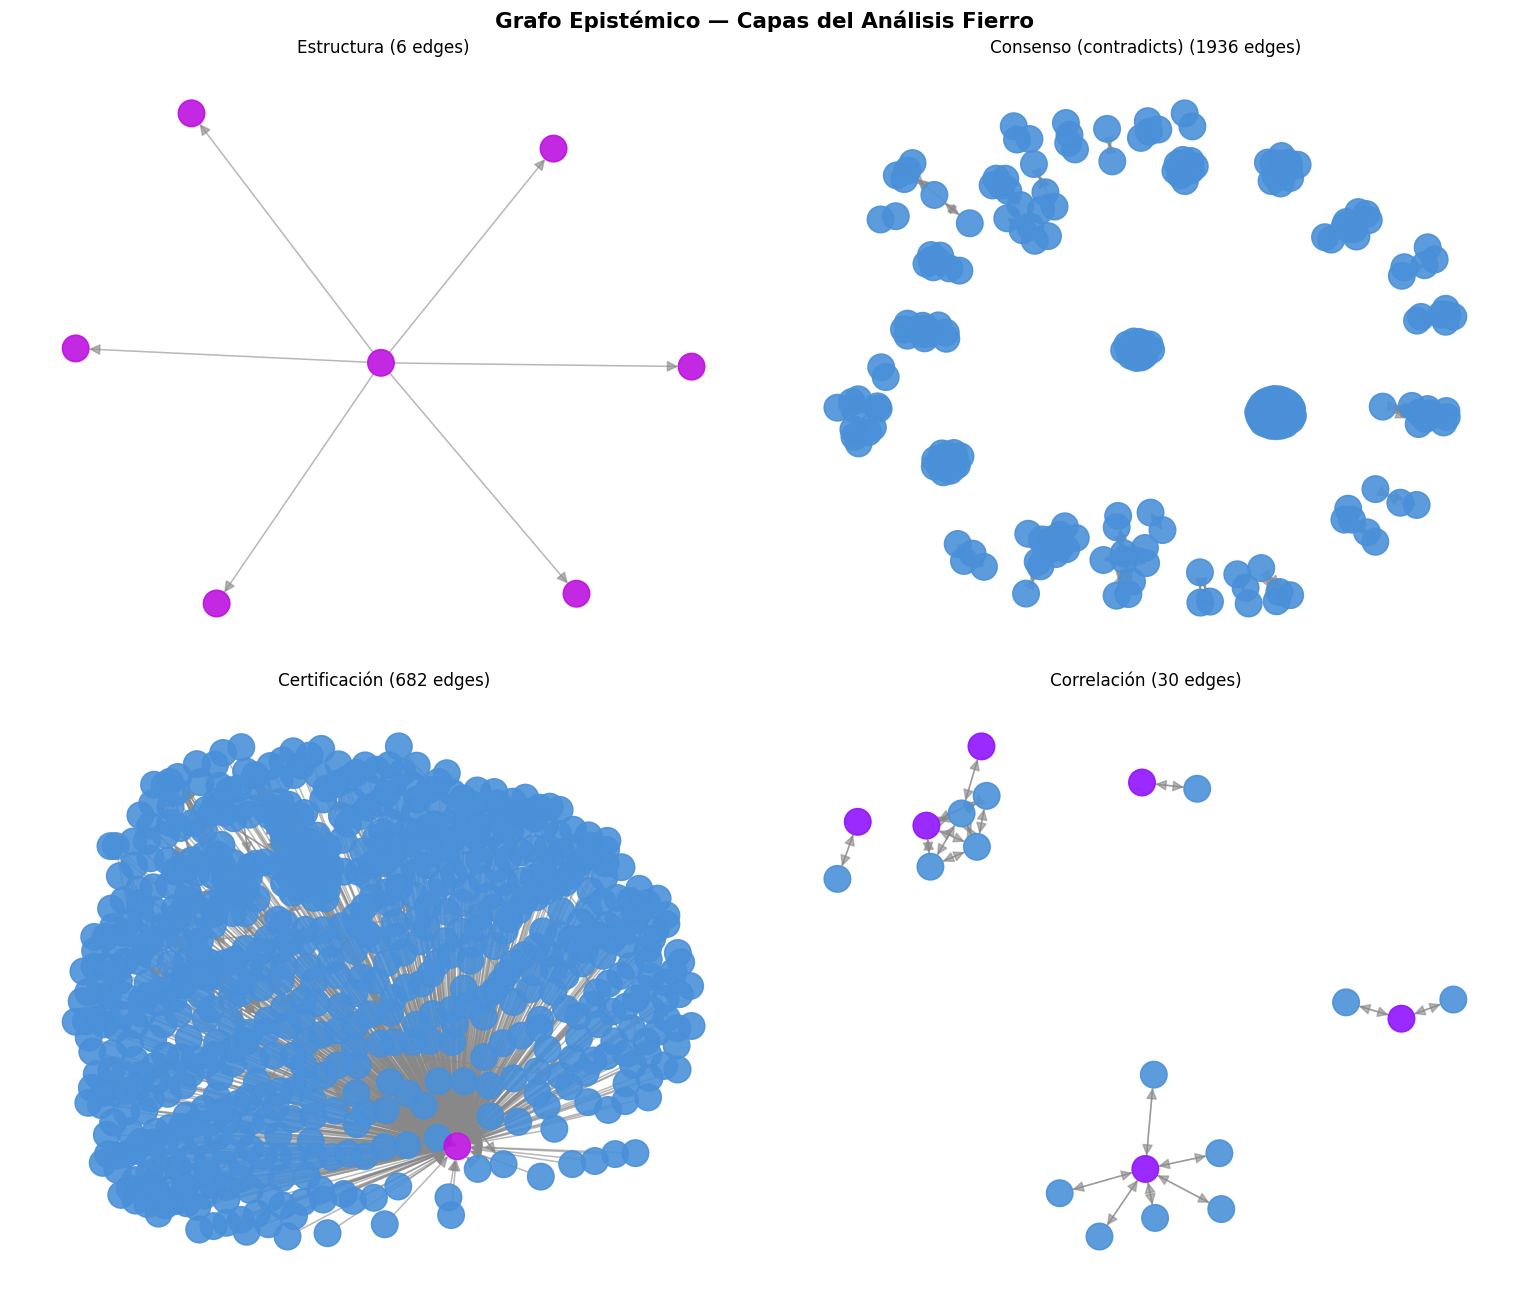

Fierro subgraph: 1061 nodes, 3850 edges
figure saved: /tmp/nb12_layers.png


In [5]:
# CELL 4: CAPAS — visualizar capas del grafo con networkx
# Focus on the Fierro subgraph + related claims (small, legible)
fig, axes = plt.subplots(2, 2, figsize=(14, 12))
fig.suptitle("Grafo Epistémico — Capas del Análisis Fierro", fontsize=14, fontweight="bold")

# Collect Fierro + carta + addendum nodes as the core set
core_ids = {n["id"] for n in fierro_nodes + carta_nodes + addendum_nodes}
# Add their immediate neighbors (1-hop)
for e in g["edges"]:
    if e["source"] in core_ids or e["target"] in core_ids:
        core_ids.add(e["source"])
        core_ids.add(e["target"])

# Build subgraph
sub_nodes = [n for n in g["nodes"] if n["id"] in core_ids]
sub_edges = [e for e in g["edges"] if e["source"] in core_ids and e["target"] in core_ids]
print(f"Fierro subgraph: {len(sub_nodes)} nodes, {len(sub_edges)} edges")

# Create networkx graph
G = nx.DiGraph()
kind_colors = {
    "claim": "#4A90D9", "answer": "#7ED321", "decision": "#F5A623",
    "predicate": "#BD10E0", "certificate": "#50E3C2", "document": "#8B572A",
    "rule": "#D0021B", "experiment": "#9013FE", "gap": "#FF6B6B",
}
for n in sub_nodes:
    G.add_node(n["id"], kind=n.get("kind", "unknown"))
for e in sub_edges:
    G.add_edge(e["source"], e["target"], kind=e["kind"])

# Draw in each layer
layers = [
    (axes[0,0], "child_of", "Estructura"),
    (axes[0,1], "contradicts", "Consenso (contradicts)"),
    (axes[1,0], "certified_by", "Certificación"),
    (axes[1,1], "correlates_with", "Correlación"),
]
for ax, layer_kind, title in layers:
    # Filter edges of this kind
    layer_edges = [(u,v) for u,v,d in G.edges(data=True) if d.get("kind")==layer_kind]
    layer_nodes = set()
    for u,v in layer_edges:
        layer_nodes.add(u); layer_nodes.add(v)
    
    if not layer_nodes:
        ax.text(0.5, 0.5, f"{title}\n(0 edges)", ha="center", va="center", fontsize=11)
        ax.set_title(title)
        ax.axis("off")
        continue
    
    H = G.subgraph(layer_nodes)
    pos = nx.spring_layout(H, k=2/np.sqrt(len(layer_nodes)), seed=42, iterations=50)
    colors = [kind_colors.get(H.nodes[n].get("kind",""), "#CCCCCC") for n in H.nodes()]
    nx.draw_networkx_nodes(H, pos, node_color=colors, node_size=300, ax=ax, alpha=0.9)
    nx.draw_networkx_edges(H, pos, edge_color="#888888", arrows=True, arrowsize=15, ax=ax, alpha=0.6)
    # Label only nodes with short ids
    labels = {n: n[:12] for n in H.nodes() if len(n) < 20}
    nx.draw_networkx_labels(H, pos, labels, font_size=7, ax=ax)
    ax.set_title(f"{title} ({len(layer_edges)} edges)", fontsize=11)
    ax.axis("off")

plt.tight_layout()
plt.savefig("/tmp/nb12_layers.png", dpi=100, bbox_inches="tight")
plt.show()
print("figure saved: /tmp/nb12_layers.png")

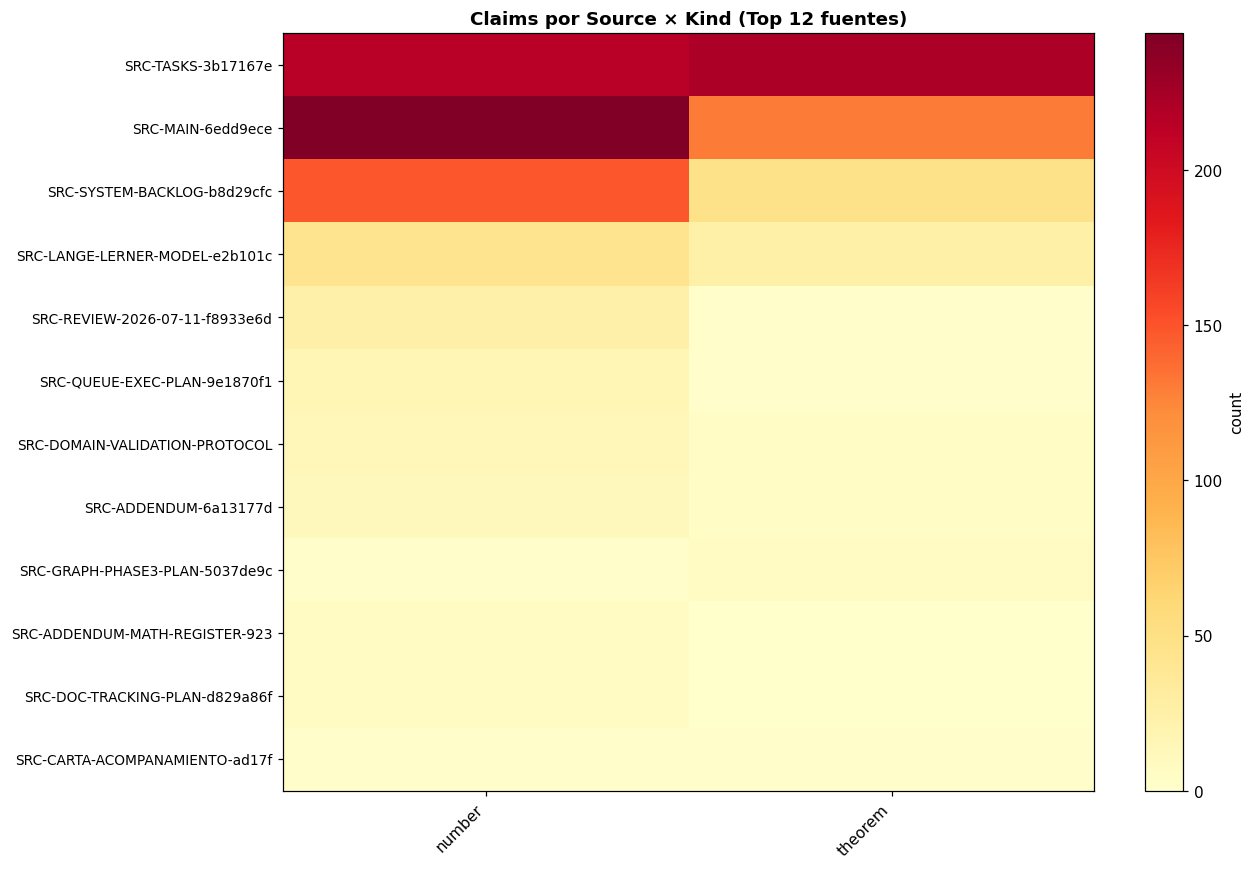

heatmap: 12 sources × 2 kinds
top source: SRC-TASKS-3b17167e (437 claims)


In [6]:
# CELL 5: CORRELACION — heatmap de co-ocurrencia de claims por source
# Parse sidecar files to get source → kind distribution
import re
from collections import Counter, defaultdict

sidecars_dir = Path("state/epistemic/sidecars")
source_kind = defaultdict(Counter)  # source_id -> kind -> count

for vf in sidecars_dir.glob("*.claims.vsm"):
    text = vf.read_text()
    # Extract source_id and type from each claim block
    for m in re.finditer(r'"source_id":\s*"([^"]+)".*?"type":\s*"([^"]+)"', text, re.DOTALL):
        sid, typ = m.group(1), m.group(2)
        source_kind[sid][typ] += 1

# Take top 12 sources by total claims
top_sources = sorted(source_kind.keys(), key=lambda s: sum(source_kind[s].values()), reverse=True)[:12]
all_types = sorted({t for c in source_kind.values() for t in c})

# Build matrix
mat = np.zeros((len(top_sources), len(all_types)), dtype=int)
for i, sid in enumerate(top_sources):
    for j, typ in enumerate(all_types):
        mat[i,j] = source_kind[sid].get(typ, 0)

fig, ax = plt.subplots(figsize=(12, 8))
im = ax.imshow(mat, cmap="YlOrRd", aspect="auto")
ax.set_xticks(range(len(all_types)))
ax.set_xticklabels(all_types, rotation=45, ha="right")
ax.set_yticks(range(len(top_sources)))
ax.set_yticklabels([s[:30] for s in top_sources], fontsize=9)
ax.set_title("Claims por Source × Kind (Top 12 fuentes)", fontsize=12, fontweight="bold")
plt.colorbar(im, label="count")
plt.tight_layout()
plt.savefig("/tmp/nb12_heatmap.png", dpi=100, bbox_inches="tight")
plt.show()
print(f"heatmap: {len(top_sources)} sources × {len(all_types)} kinds")
print(f"top source: {top_sources[0][:40]} ({sum(source_kind[top_sources[0]].values())} claims)")

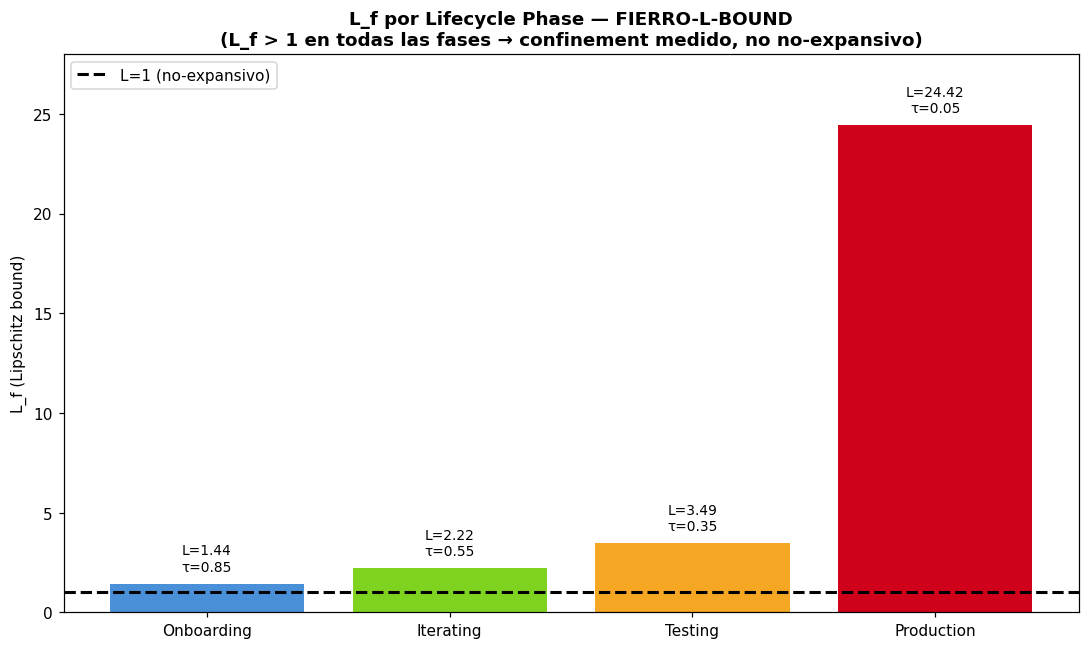

L_f range: [1.44, 24.42]
All phases L_f > 1: True
→ Claim L≤1 OFF-core WITHDRAWN; replaced by measured confinement


In [7]:
# CELL 6: L_F POR LIFECYCLE — gráfico de barras del Lipschitz bound
# Datos: FIERRO-L-BOUND (REVIEW_2026-07-11.md Appendix A)
lifecycle_data = [
    ("Onboarding", 0.2, 0.85, 1.436),
    ("Iterating", 0.5, 0.55, 2.220),
    ("Testing", 0.7, 0.35, 3.488),
    ("Production", 1.0, 0.05, 24.418),
]

phases = [d[0] for d in lifecycle_data]
lf_vals = [d[3] for d in lifecycle_data]
taus = [d[2] for d in lifecycle_data]

fig, ax = plt.subplots(figsize=(10, 6))
bars = ax.bar(phases, lf_vals, color=["#4A90D9", "#7ED321", "#F5A623", "#D0021B"])
ax.axhline(y=1.0, color="black", linestyle="--", linewidth=2, label="L=1 (no-expansivo)")
ax.set_ylabel("L_f (Lipschitz bound)")
ax.set_title("L_f por Lifecycle Phase — FIERRO-L-BOUND\n(L_f > 1 en todas las fases → confinement medido, no no-expansivo)",
             fontsize=12, fontweight="bold")
ax.legend()
ax.set_ylim(0, 28)

# Annotate bars
for bar, lf, tau in zip(bars, lf_vals, taus):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.5,
            f"L={lf:.2f}\nτ={tau}", ha="center", va="bottom", fontsize=9)

plt.tight_layout()
plt.savefig("/tmp/nb12_lipschitz.png", dpi=100, bbox_inches="tight")
plt.show()
print(f"L_f range: [{min(lf_vals):.2f}, {max(lf_vals):.2f}]")
print(f"All phases L_f > 1: {all(v > 1 for v in lf_vals)}")
print("→ Claim L≤1 OFF-core WITHDRAWN; replaced by measured confinement")

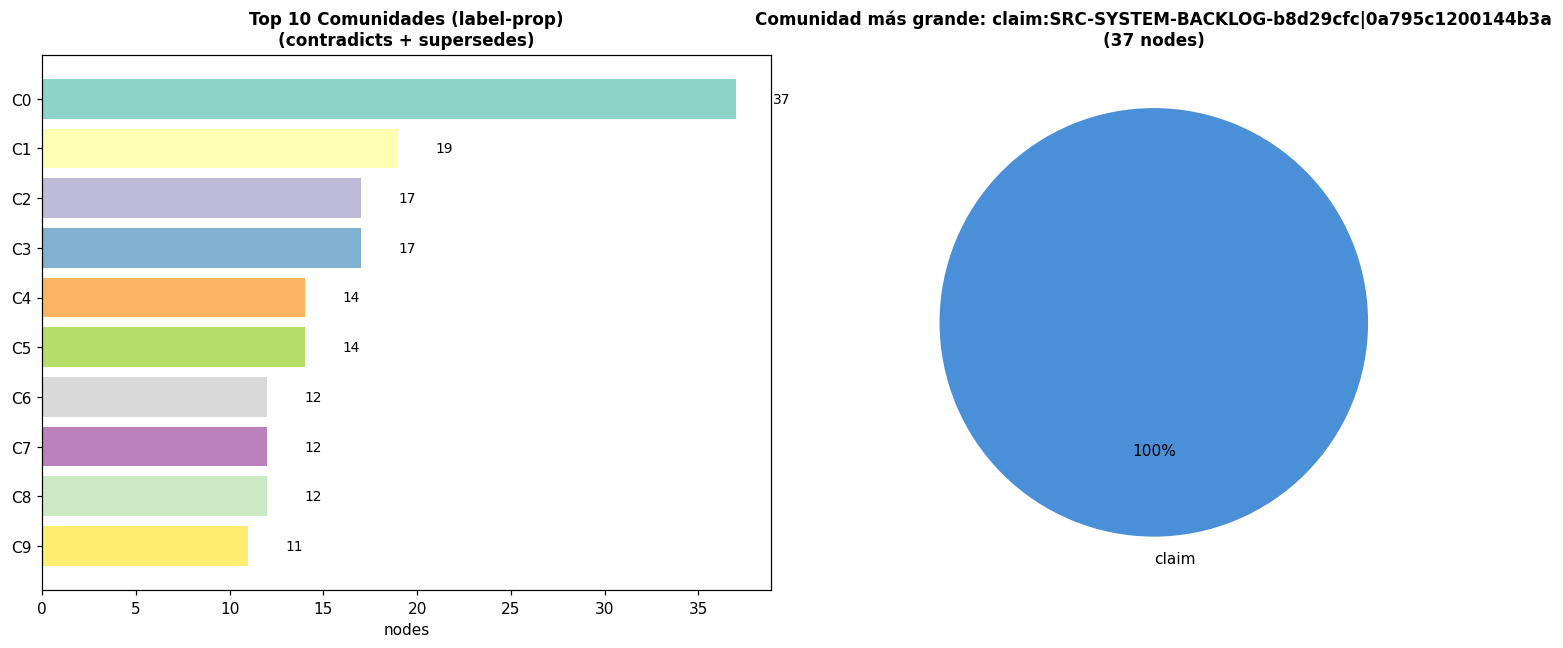

Total comunidades: 71
Top 10 sizes: [37, 19, 17, 17, 14, 14, 12, 12, 12, 11]
Largest community kind mix: {'claim': 37}


In [8]:
# CELL 7: COMMUNIDADES — label-prop del grafo completo, top 10
comm = communities(g, ("contradicts", "supersedes"))
comm_sizes = Counter(comm.values())
top10 = comm_sizes.most_common(10)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))

# Bar chart of community sizes
comm_ids = [f"C{i}" for i,_ in enumerate(top10)]
sizes = [s for _,s in top10]
colors = plt.cm.Set3(np.linspace(0, 1, 10))
ax1.barh(comm_ids[::-1], sizes[::-1], color=colors[::-1])
ax1.set_xlabel("nodes")
ax1.set_title("Top 10 Comunidades (label-prop)\n(contradicts + supersedes)", fontsize=11, fontweight="bold")
for i, (cid, sz) in enumerate(top10):
    ax1.text(sz + 2, 9-i, str(sz), va="center", fontsize=9)

# Pie chart of node kind distribution in top community
top_comm_id = top10[0][0]
top_comm_nodes = [n for n in g["nodes"] if comm.get(n["id"]) == top_comm_id]
kind_dist = Counter(n.get("kind", "unknown") for n in top_comm_nodes)
kinds = list(kind_dist.keys())
kcounts = list(kind_dist.values())
kind_colors = {"claim": "#4A90D9", "answer": "#7ED321", "decision": "#F5A623",
               "predicate": "#BD10E0", "certificate": "#50E3C2", "rule": "#D0021B",
               "experiment": "#9013FE", "gap": "#FF6B6B", "document": "#8B572A"}
pie_colors = [kind_colors.get(k, "#CCCCCC") for k in kinds]
ax2.pie(kcounts, labels=kinds, colors=pie_colors, autopct="%1.0f%%", startangle=90)
ax2.set_title(f"Comunidad más grande: {top_comm_id}\n({len(top_comm_nodes)} nodes)", fontsize=11, fontweight="bold")

plt.tight_layout()
plt.savefig("/tmp/nb12_communities.png", dpi=100, bbox_inches="tight")
plt.show()
print(f"Total comunidades: {len(comm_sizes)}")
print(f"Top 10 sizes: {[s for _,s in top10]}")
print(f"Largest community kind mix: {dict(kind_dist)}")

In [9]:
# CELL 8: SUMMARY — tabla Q→Resp→Estado
print("=" * 80)
print("RESUMEN: Fierro Objections → vOS Response → Status")
print("=" * 80)
print(f"{'Q':<4} {'Topic':<25} {'Solution':<35} {'Status':<12}")
print("-" * 80)
summary = [
    ("Q1", "convexidad de Ω", "Prop1: Krylov-Bogolyubov + Banach", "RESUELTA"),
    ("Q2", "invariancia de f₀", "Confinamiento medido (L_f, zero exits)", "RESUELTA"),
    ("Q3", "ruido no acotado", "Prop2: Foster-Lyapunov drift", "RESUELTA"),
]
for q, topic, sol, status in summary:
    print(f"{q:<4} {topic:<25} {sol:<35} {status:<12}")
print("=" * 80)
print("\nFIGURES SAVED:")
for f in ["nb12_layers.png", "nb12_heatmap.png", "nb12_lipschitz.png", "nb12_communities.png"]:
    print(f"  /tmp/{f}")
print("\nGRAPH STATS:")
print(f"  Full graph: {g['meta']['nodes_total']} nodes / {g['meta']['edges_total']} edges")
print(f"  Fierro subgraph: {len(sub_nodes)} nodes / {len(sub_edges)} edges")
print(f"  Communities: {len(comm_sizes)}")
print(f"  L_f range: [{min(lf_vals):.2f}, {max(lf_vals):.2f}]")

RESUMEN: Fierro Objections → vOS Response → Status
Q    Topic                     Solution                            Status      
--------------------------------------------------------------------------------
Q1   convexidad de Ω           Prop1: Krylov-Bogolyubov + Banach   RESUELTA    
Q2   invariancia de f₀         Confinamiento medido (L_f, zero exits) RESUELTA    
Q3   ruido no acotado          Prop2: Foster-Lyapunov drift        RESUELTA    

FIGURES SAVED:
  /tmp/nb12_layers.png
  /tmp/nb12_heatmap.png
  /tmp/nb12_lipschitz.png
  /tmp/nb12_communities.png

GRAPH STATS:
  Full graph: 2227 nodes / 4962 edges
  Fierro subgraph: 1061 nodes / 3850 edges
  Communities: 71
  L_f range: [1.44, 24.42]
